### Análisis y Procesamiento de Señales, 2°C 2026

# TS7: Filtrado digital lineal de ECG

### <u>Integrantes de grupo</u>:
#### - Rey, Tomás 
#### - Lanzavechia, Jerónimo
#### - Alvarez Costa, Iara 
#### - Costenla, Gonzalo 


## <u>Introducción</u>

En la Tarea Semanal N°5 se analizó, entre otras, una señal electrocardiográfica sin perturbaciones, para comparar distintos métodos de estimación espectral, y estimar el ancho de banda de la señal. Para esta tarea será de interés trabajar con la versión contaminada de esa misma señal para estudiar las características de distintos métodos de filtrado digital lineal.

El electrocardiograma (ECG) es una señal de muy baja amplitud, por lo que su registro es sensible a fuentes de contaminación. Se tiene un registro de un paciente durante una prueba de esfuerzo, y se reconocen las siguientes tres fuentes de ruido:

- **Movimiento de los electrodos**, de alta frecuencia.
- **Ruido muscular**, de alta frecuencia.
- **Movimiento de la línea de base**, inducido en parte por la respiración, de baja frecuencia.


#### Parte a)
Dado que el contenido espectral útil del ECG se encuentra en una banda acotada, mientras que estas perturbaciones se ubican en sus extremos, estas distorsiones pueden ser atenuadas por un filtro pasabanda. El objetivo es obtener una señal suave y con nivel isoeléctrico nulo, cuya morfología sea comparable con la de los latidos promedio de referencia (normal y de origen ventricular).

Para ello se establece una plantilla de diseño a partir del ancho de banda del ECG estimado en la TS5 (Aproximadamente unos 22 kHz), y se diseñan y comparan filtros IIR (aproximaciones de Butterworth, Chebyshev tipo II y Cauer) y FIR (métodos de ventanas, cuadrados mínimos y Parks-McClellan-Remez), todos implementados con `scipy.signal`. Finalmente, se evalúa el desempeño de cada filtro, verificando que atenue el ruido que deseamos eliminar sin distorsionar la sección de la señal que es de nuestro interés.

In [3]:
import numpy as np
from scipy import signal as sig

import matplotlib.pyplot as plt
   
import scipy.io as sio
from scipy.io.wavfile import write
from matplotlib.patches import Rectangle

In [4]:
##Obtención de la señal ECG
##################
## ECG con ruido
##################

fs=1000 #definimos la frecuencia de muestreo en 1000 hz

# para listar las variables que hay en el archivo
sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead']*1.0
ecg_one=ecg_one_lead[5000:12000].flatten()
#ecg_one_lead=ecg_one
N = len(ecg_one_lead)
y_min, y_max = -100, 5

In [5]:
#############
# Plantilla #
#############
 
nyq_frec = fs/2
ripple = 1 # dB
atenuacion = 40 # dB
 
ws1 = 2 # Hz
wp1 = 5 # Hz
wp2 = 25 # Hz
ws2 = 35 # Hz
wp=[wp1, wp2]
ws=[ws1, ws2]

#### Parte b)

Para hallar la frecuencia de paso, $w_{p1}$ y $w_{p2}$, las mismas se fijaron 5 y 25 Hz como margenes interiores, respectivamente. En la TS5, se determinó que el ancho de banda de la señal ECG que se está trabajando es de unos 22 kHz aproximadamente, por lo que con este rango se asegura atrapar todo el contendio espectral.

Para hallar la frecuencia de rechazo, $w_{s1}$ y $w_{s2}$, se establecieron como márgenes exteriores 2 y 35 Hz, respectivamente. El motivo de estas selecciones es que, a baja frecuencia, el movimiento de la linea base inducido por la respiración genera ruido que se busca atenuar. Mismamente, luego de los 35 hz también hay ruido, del tipo muscular y por movimientos del electrodo.

El ripple en la banda de paso se estableció en 1 dB ya que es la máxima variación que quiero permitirle a mi señal dentro de la banda de paso.

La atenuación en la banda de rechazo se estableció en 40 dB para asegurarme de que las fuentes de ruido mencionadas queden atenuadas y no afecten la señal de interés.

#### Parte c)
Usamos la función `iirdesign`  para armar los filtros IIR. `wp` y `ws` entran como listas de elementos, y pedimos que devuelva una variable `sos`, es decir, second order sections, que es el filtro partido en una cascada de secciones de segundo orden. 

In [18]:
#Filtros IIR

sos_butt = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='butter', fs=fs, output = 'sos')
sos_cheby2 = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='cheby2', fs = fs, output = 'sos')
sos_cauer = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='cauer', fs = fs, output = 'sos')

In [19]:
def calc_resp(sos, leg_str, fig_n_axes):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    f, h = sig.freqz_sos(sos, worN=8192, fs=fs)

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega), en segundos
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    # Donde el filtro rechaza la señal, el retardo no es significativo
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)
    ax_mod.legend()

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    for w in wp:
        ax_fase.axvline(w, color="gray", linestyle=":")
    for w in ws:
        ax_fase.axvline(w, color="gray", linestyle="--")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)
    ax_fase.legend()

    # --- Retardo de grupo ---
    ax_retardo.plot(f, retardo_s_plot, label=leg_str)

    for w in wp:
        ax_retardo.axvline(w, color="orange", linestyle="--")

    for w in ws:
        ax_retardo.axvline(w, color="red", linestyle=":")

    ax_retardo.set_xlabel("Frecuencia (Hz)")
    ax_retardo.set_ylabel("Retardo de grupo (s)")
    ax_retardo.set_title("Retardo de grupo del filtro IIR")
    ax_retardo.grid(True)
    ax_retardo.legend()

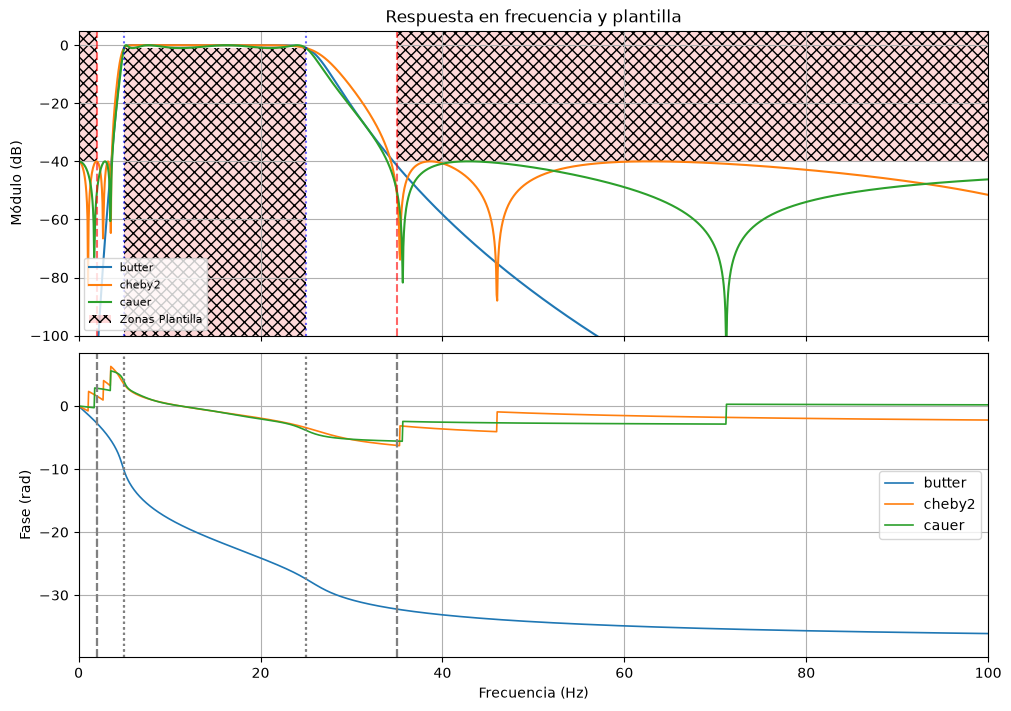

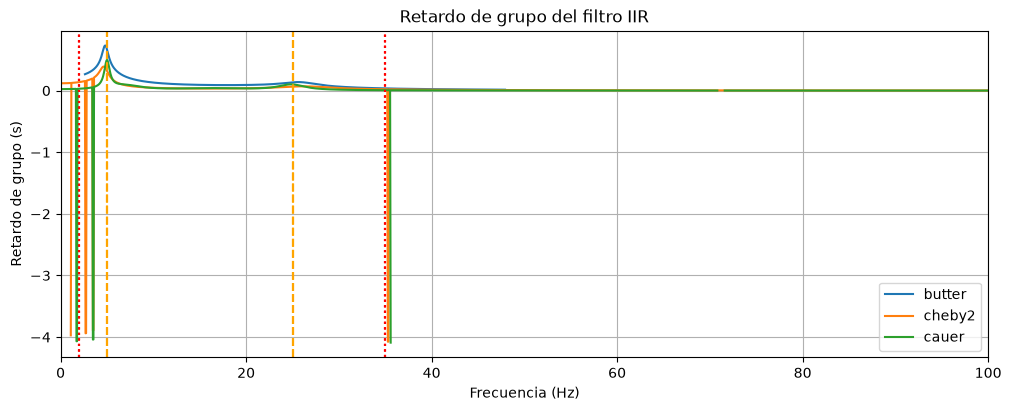

In [20]:
plt.close('all')

fig_n_axes = plt.subplots(
    2, 1, sharex=True, num=1, figsize=(10, 7), constrained_layout=True
)

fig_retardo, ax_retardo = plt.subplots(
    num=2, figsize=(10, 4), constrained_layout=True
)

calc_resp(sos_butt,   'butter', fig_n_axes)
calc_resp(sos_cheby2, 'cheby2', fig_n_axes)
calc_resp(sos_cauer,  'cauer',  fig_n_axes)

# Plantilla sobre el gráfico de módulo
ax_mod = fig_n_axes[1][0]

# Zona prohibida en rechazo: de -atenuacion hacia arriba
ax_mod.add_patch(Rectangle((0, -atenuacion), ws1, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))
ax_mod.add_patch(Rectangle((ws2, -atenuacion), nyq_frec - ws2, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))

# Franja prohibida bajo el ripple, en la banda de paso
ax_mod.add_patch(Rectangle((wp1, y_min), wp2 - wp1, -ripple - y_min,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx",
                           label='Zonas Plantilla'))

# Límites de las bandas
for w in wp:
    ax_mod.axvline(w, color="blue", linestyle=":", alpha=0.6)
for w in ws:
    ax_mod.axvline(w, color="red", linestyle="--", alpha=0.6)

ax_mod.legend(loc="lower left", fontsize=8)
ax_mod.set_xlim(0, 100)          
# Retardo de grupo (figura 2)
plt.figure(2)
plt.xlim(0, 100)                 
plt.show()                       

Los tres filtros cumplen con las especificaciones de atenuación en módulo fuera de las bandas de paso. El filtro hecho con Cauer presenta oscilaciones visibles pero menores a 1 dB de amplitud en las bandas de paso, contrastando con los filtros aproximados por Butterworth y Chevyshev II, cuya respuesta permanece mayormente plana en el mismo rango frecuencial.

Ninguno de los filtros muestra una respuesta de fase continuamente lineal en toda la banda analizada. El filtro Butterworth presenta una variación de fase más pronunciada en el rango dpróximo a la banda de paso, mientras que los filtros Chebyshev tipo II y Cauer muestran un par de cambios abruptos (o saltos) en las frecuencias coincidentes con la minimización abrupta de su módulo, presumiblemente debido a la presencia de ceros de transmisión en la banda de rechazo.

El retardo de grupo también refuerza la evidencia de que los filtros no son perfectamente lineales. En todos los casos de pueden observar ligeras variaciones del retardo en función de la frecuencia, particularmente en las regiones próximas a la banda de transición. 



#### Ahora aplicamos los 3 filtros IIR a la señal:

In [ ]:
ecg_one_1d=ecg_one.ravel()

ecg_filt_butt=sig.sosfiltfilt(sos_butt,ecg_one_1d)
ecg_filt_cheby2=sig.sosfiltfilt(sos_cheby2,ecg_one_1d)
ecg_filt_cauer=sig.sosfiltfilt(sos_cauer,ecg_one_1d)

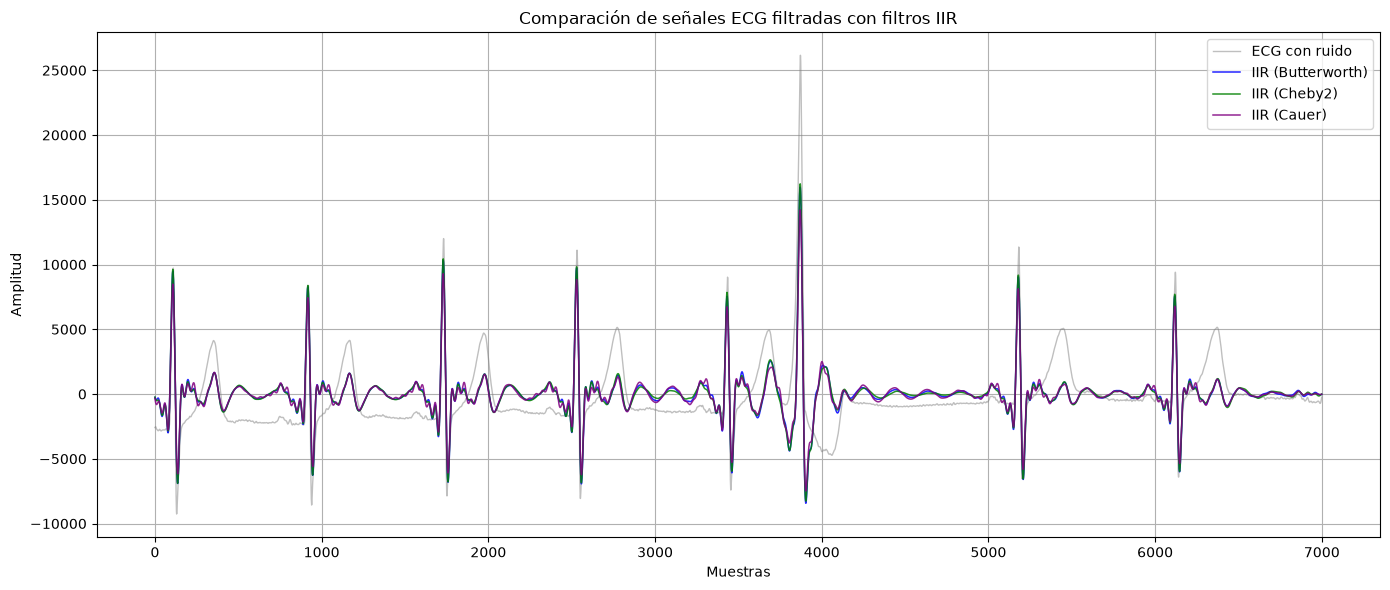

In [42]:
def plotear_todas_iir_juntas(ecg_orig, dic_filtradas_iir):
    plt.figure(figsize=(14, 6))
    # Graficamos la señal original con ruido de fondo
    plt.plot(ecg_orig, label='ECG con ruido', color='gray', alpha=0.5, linewidth=1)
    
    colores = ['blue', 'green', 'purple']
    
    for (nombre, ecg_filt), color in zip(dic_filtradas_iir.items(), colores):
        # Como usamos sosfiltfilt (fase cero), no hay retardo que compensar
        plt.plot(ecg_filt, label=f'IIR ({nombre})', color=color, linewidth=1.1, alpha=0.85)
        
    plt.title("Comparación de señales ECG filtradas con filtros IIR")
    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


    # Diccionario con las señales IIR filtradas
dic_iir_filtradas = {
    'Butterworth': ecg_filt_butt,
    'Cheby2': ecg_filt_cheby2,
    'Cauer': ecg_filt_cauer
}

# --- Llamamos a la función ---
plotear_todas_iir_juntas(ecg_one, dic_iir_filtradas)


#### Análisis

Lo primero que salta a la vista es el efecto mitigante que todos los filtros tienen sobre las perturbaciones de baja frecuencia presentes en la señal original.

Las 3 curvas correspondientes a la señal filtrada se superponen en gran parte del registro, lo cual es coherente con los tres filtros habiendo sido diseñados con los mismos parámetros de plantilla.

Sin embargo, se pueden observar ligeras diferencias en determinadas regiones del registro, las cuales son más evidentes al ampliar una zona arbitraria del gráfico:


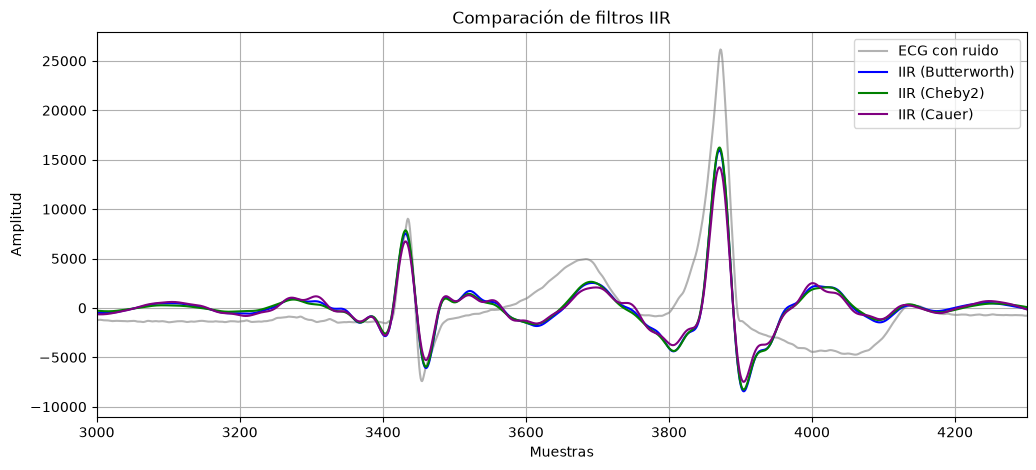

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(ecg_one_1d, color='gray', alpha=0.6,
         label='ECG con ruido')

plt.plot(ecg_filt_butt, color='blue', label='IIR (Butterworth)')
plt.plot(ecg_filt_cheby2, color='green', label='IIR (Cheby2)')
plt.plot(ecg_filt_cauer, color='purple', label='IIR (Cauer)')

plt.xlim(3000, 4300)

plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.title('Comparación de filtros IIR')

plt.grid(True)
plt.legend()
plt.show()

Podemos ver que las zonas de amplitud más elevada son las que mas distinción evidencian entre las señales filtradas, siendo las filtradas con Butterworth y Chebyshev las que muestran mayor acentuación en los picos de amplitud. 
